# Homework 2 — Machine Learning Regression

## Homework Objective

The objective of this homework is to build and evaluate a **linear regression model** for predicting `fuel_efficiency_mpg` using vehicle characteristics.

The notebook covers data preparation, train/validation/test splitting, missing-value handling, linear regression, regularization, sensitivity to random seeds, and final test evaluation.

**Target:** `fuel_efficiency_mpg`  
**Features:** `engine_displacement`, `horsepower`, `vehicle_weight`, `model_year`


# Cohort Homework-02 regression model

In [1]:
# Importing modules
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

## Loading data

In [2]:
data_path = "..\data\car_fuel_efficiency_2026.csv"

df = pd.read_csv(data_path)

df.head(1)

,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
0,2006,Europe,Gasoline,Front-wheel drive,4,2180,6,243.0,3870,NaN,31.9


Understanding the data set and cleaning

In [3]:
rows , columns = df.shape
(rows,columns)

(10000, 11)

In [4]:
column_names = list(df.columns)
col_details = []
for col in column_names :
    col_details.append([col, df[col].nunique(), df[col].isnull().sum(), df[col].dtype.name])

col_details_table = pd.DataFrame(col_details, columns=['name','no_of_unique_values','no_null_values','datatypes'])

col_details_table

,name,no_of_unique_values,no_null_values,datatypes
0,model_year,50,0,int64
1,origin,3,0,str
2,fuel_type,3,0,str
3,drivetrain,3,0,str
4,num_doors,4,0,int64
5,engine_displacement,127,0,int64
6,num_cylinders,5,0,int64
7,horsepower,153,877,float64
8,vehicle_weight,176,0,int64
9,acceleration,93,264,float64


In [5]:
df["horsepower"].describe()

count    9123.000000
mean      254.446016
std        22.844613
min       171.000000
25%       239.000000
50%       254.000000
75%       270.000000
max       334.000000
Name: horsepower, dtype: float64

In [6]:
df["horsepower"].median()
np.percentile(df['horsepower'].dropna(), 50)

np.float64(254.0)

# EDA

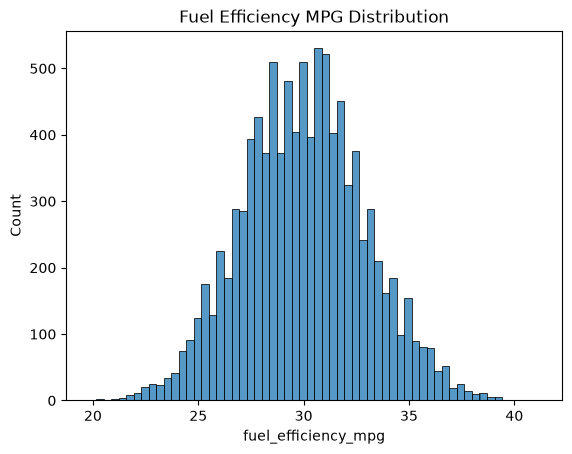

In [7]:
#  1) Raw fuel_efficiency_mpg distribution

sns.histplot(data=df, x='fuel_efficiency_mpg')
plt.title('Fuel Efficiency MPG Distribution')
plt.show()

# Train test spilts

In [8]:
# removing null values

# df['horsepower'] = df['horsepower'].fillna(0)
# df['acceleration'] = df['acceleration'].fillna(0)

# df['horsepower'] = df['horsepower'].fillna(df['horsepower'].mean())
# df['acceleration'] = df['acceleration'].fillna(df['acceleration'].mean())

In [9]:
df['horsepower'] = df['horsepower'].fillna(0)
# df['horsepower'] = df['horsepower'].fillna(df['horsepower'].mean())

n = len(df)
n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

np.random.seed(42)
idx = np.arange(n)
np.random.shuffle(idx)

df_train = df.iloc[idx[:n_train]]
df_val = df.iloc[idx[n_train:n_train + n_val]]
df_test = df.iloc[idx[n_train + n_val:]]

# n,len(df_train), len(df_val), len(df_test)

# Reset row labels so each set is indexed 0..len-1
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

Target separation

In [10]:
y_train = df_train.fuel_efficiency_mpg.values
y_val = df_val.fuel_efficiency_mpg.values
y_test = df_test.fuel_efficiency_mpg.values

del df_train['fuel_efficiency_mpg']
del df_val['fuel_efficiency_mpg']
del df_test['fuel_efficiency_mpg']

In [11]:
# df_train.isnull().sum() , df_val.isnull().sum() , df_test.isnull().sum()

# Training Regression model

In [12]:
def train_regression(X,y) :
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XtX = np.dot(X.T,X)
    XtX_inv = np.linalg.inv(XtX)

    weights = np.dot(np.dot(XtX_inv,X.T), y)

    bias = weights[0]
    feature_weights = weights[1:]

    return bias,feature_weights

def prep_X(Df):
    return Df[baseline].values

baseline = ['engine_displacement','horsepower','vehicle_weight','model_year']

In [13]:
X_train = prep_X(df_train)

W0 , W = train_regression(X_train,y_train)

y_pred = W0 + np.dot(X_train, W)

y_pred

array([34.07471478, 29.24093577, 32.95179055, ..., 29.32203017,
       31.8448482 , 29.69112172], shape=(6000,))

<Axes: ylabel='Count'>

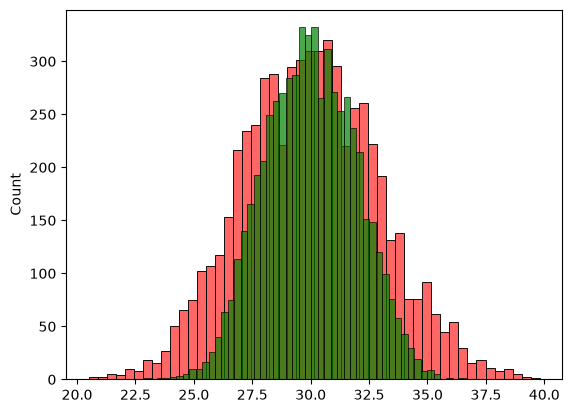

In [14]:
sns.histplot(y_train, color="red", alpha=0.6, bins=50)
sns.histplot(y_pred, color="green", alpha=0.7, bins=50)

In [15]:
def rmse(y, y_pred):
    error = y - y_pred
    squared_error = error ** 2
    mse = squared_error.mean()
    return round(np.sqrt(mse),3)


rmse(y_train, y_pred)

np.float64(2.2)

Train model with regularization

In [16]:
def train_regression_reg(X,y,r) :
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XtX = np.dot(X.T,X)

    identity = np.eye(X.shape[1])

    XtX_reg = XtX + r * identity

    XtX_inv = np.linalg.inv(XtX_reg)

    weights = np.dot(np.dot(XtX_inv,X.T), y)

    bias = weights[0]
    feature_weights = weights[1:]

    return bias,feature_weights

def prep_X(Df):
    return Df[baseline].values

baseline = ['engine_displacement','horsepower','vehicle_weight','model_year']

In [17]:
# df_train = df.iloc[idx[:n_train]]
# df_val = df.iloc[idx[n_train:n_train + n_val]]
# df_test = df.iloc[idx[n_train + n_val:]]

# y_train = df_train.fuel_efficiency_mpg.values
# y_val = df_val.fuel_efficiency_mpg.values
# y_test = df_test.fuel_efficiency_mpg.values

In [18]:
X_val = prep_X(df_val)

for r in [0, 0.01, 0.1, 1, 5, 10, 100]:

    W0 , W = train_regression_reg(X_train,y_train,r)

    y_pred = W0 + np.dot(X_val, W)

    print(r," ->" ,rmse(y_val, y_pred))

0  -> 2.205
0.01  -> 2.206
0.1  -> 2.224
1  -> 2.349
5  -> 2.409
10  -> 2.419
100  -> 2.429


In [19]:
df['horsepower'] = df['horsepower'].fillna(0)
# df['horsepower'] = df['horsepower'].fillna(df['horsepower'].mean())

def split(df, seed = 42):
    n = len(df)
    n_val = int(n * 0.2)
    n_test = int(n * 0.2)
    n_train = n - n_val - n_test

    np.random.seed(seed)
    idx = np.arange(n)
    np.random.shuffle(idx)

    df_train = df.iloc[idx[:n_train]]
    df_val = df.iloc[idx[n_train:n_train + n_val]]
    df_test = df.iloc[idx[n_train + n_val:]]

    # n,len(df_train), len(df_val), len(df_test)

    # Reset row labels so each set is indexed 0..len-1
    df_train = df_train.reset_index(drop=True)
    df_val = df_val.reset_index(drop=True)
    df_test = df_test.reset_index(drop=True)

    y_train = df_train.fuel_efficiency_mpg.values
    y_val = df_val.fuel_efficiency_mpg.values
    y_test = df_test.fuel_efficiency_mpg.values

    del df_train['fuel_efficiency_mpg']
    del df_val['fuel_efficiency_mpg']
    del df_test['fuel_efficiency_mpg']

    X_train = prep_X(df_train)
    X_val = prep_X(df_val)
    X_test = prep_X(df_test)

    return X_train, y_train, X_val, y_val, X_test, y_test

scores = []

for seed in range(10):

    X_train, y_train, X_val, y_val, X_test, y_test = split(df, seed)

    W0, W = train_regression(X_train, y_train)

    y_pred = W0 + np.dot(X_val, W)

    score = rmse(y_val, y_pred)

    scores.append(score)

    print(seed, "->", score)

print("\nstd:", round(np.std(scores), 3))

0 -> 2.239
1 -> 2.202
2 -> 2.163
3 -> 2.204
4 -> 2.202
5 -> 2.246
6 -> 2.27
7 -> 2.191
8 -> 2.217
9 -> 2.207

std: 0.029


In [20]:
def q6_model(df):
    # Split using seed 9
    X_train, y_train, X_val, y_val, X_test, y_test = split(df, seed=9)

    # Combine train + validation
    X_train_full = np.vstack([X_train, X_val])
    y_train_full = np.concatenate([y_train, y_val])

    # Train regularized model
    W0, W = train_regression_reg(
        X_train_full,
        y_train_full,
        r=0.001
    )

    # Predict on test
    y_pred = W0 + np.dot(X_test, W)

    # Test RMSE
    return rmse(y_test, y_pred)

score = q6_model(df)

print("Test RMSE:", round(score, 3))

Test RMSE: 2.236


## Final Answers

EDA : 

### Question 1
ans: **`'horsepower'`**

### Question 2
ans: **`254`**

### Question 3
ans: Both are equally good

### Question 4
ans: Best regularization parameter: **`r = 0`** based on the validation RMSE results.

### Question 5
ans: RMSE standard deviation **`0.029`**

### Question 6
Test RMSE: **`2.236`** 
